# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** _(paste your Streamlit URL)_

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [17]:
# Shape
print('Shape:', df.shape)
print()

# Column types
print('Column types:')
print(df.dtypes)
print()

# Missing values
print('Missing values:')
print(df.isnull().sum())
print()

# Duplicates
print('Duplicate rows:', df.duplicated().sum())
print()

# Numeric ranges
print('Numeric summary:')
print(df.describe())

Shape: (100000, 13)

Column types:
user_id          int64
movie_id         int64
rating           int64
timestamp          str
age              int64
gender             str
occupation         str
zip_code           str
title              str
year           float64
decade         float64
genres             str
rating_year      int64
dtype: object

Missing values:
user_id         0
movie_id        0
rating          0
timestamp       0
age             0
gender          0
occupation      0
zip_code        0
title           0
year           30
decade         30
genres          0
rating_year     0
dtype: int64

Duplicate rows: 0

Numeric summary:
            user_id       movie_id         rating            age  \
count  100000.00000  100000.000000  100000.000000  100000.000000   
mean      462.48475     425.530130       3.529860      32.969850   
std       266.61442     330.798356       1.125674      11.562623   
min         1.00000       1.000000       1.000000       7.000000   
25%       2

**✏️ Data notes:** The dataset has 100,000 rows and 13 columns with zero duplicates. The only missing values are in `year` and `decade` (30 rows each), which correspond to movies whose release year couldn't be parsed from the title. All ratings are integers from 1 to 5 (mean ≈ 3.53). There are 943 unique users and 1,682 unique movies. Movie release years span 1922–1998, but all ratings were given in just two years: 1997 and 1998. I'll drop the 30 rows with missing `year` only for Q3 (the time trend question) since they can't be placed on the timeline, but keep them for everything else.

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: I'll count **ratings** per genre, after exploding multi-genre movies so each genre gets credit for every rating. A movie tagged "Crime|Thriller" adds one rating to both Crime and Thriller.
- Why: Counting ratings tells us what people actually watched and reviewed, not just what was available. Exploding is the standard way to handle multi-label data. I'll note that percentages add up to more than 100% because of the overlap.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: I'll compute the mean of **all individual ratings** within each genre (after exploding). I'll keep all genres but show the count alongside each average so the reader can judge reliability.
- Why: Averaging all ratings weights popular movies more, which reflects what most viewers experienced. Showing the count lets the reader discount genres with tiny samples (like "unknown" with only 10 ratings).

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: I'll drop the 30 rows with missing `year` and plot mean rating by movie release year. I'll also show the count of ratings per year so the reader can see where the data is thin.
- Why: 30 missing rows out of 100,000 is negligible. The count overlay is essential because early decades have very few ratings (e.g., 18 for 1930) compared to the 1990s (tens of thousands), so averages from sparse years are unreliable.

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: A movie's rating is the mean of all its individual user ratings. "At least 50" means ≥ 50. Ties are broken by showing all tied movies (if any), but I'll sort secondarily by count (more ratings = stronger evidence).
- Why: ≥ is the natural reading of "at least." Using the mean of all user ratings is the simplest and most standard approach.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

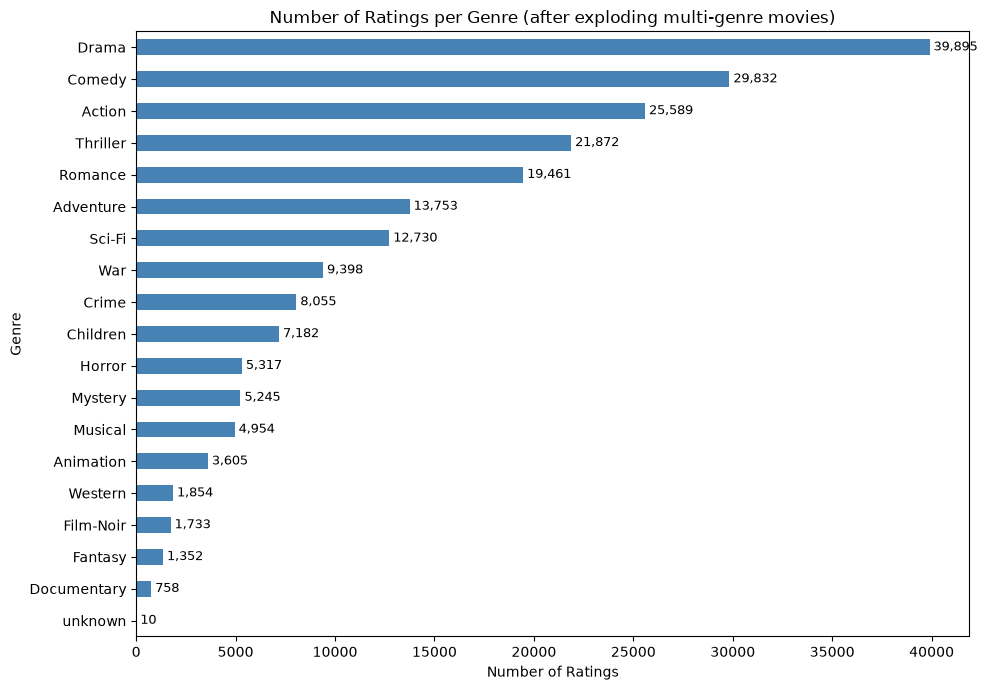

genre
Drama          39895
Comedy         29832
Action         25589
Thriller       21872
Romance        19461
Adventure      13753
Sci-Fi         12730
War             9398
Crime           8055
Children        7182
Horror          5317
Mystery         5245
Musical         4954
Animation       3605
Western         1854
Film-Noir       1733
Fantasy         1352
Documentary      758
unknown           10
Name: count, dtype: int64


In [19]:
# Q1: Explode genres and count ratings per genre
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
genre_counts = genre_df['genre'].value_counts()

# Horizontal bar chart (sorted, readable labels)
fig, ax = plt.subplots(figsize=(10, 7))
genre_counts.sort_values().plot.barh(ax=ax, color='steelblue')
ax.set_xlabel('Number of Ratings')
ax.set_ylabel('Genre')
ax.set_title('Number of Ratings per Genre (after exploding multi-genre movies)')

# Add count labels on bars
for i, (val, name) in enumerate(zip(genre_counts.sort_values(), genre_counts.sort_values().index)):
    ax.text(val + 200, i, f'{val:,}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print(genre_counts)

**✏️ My answer (with numbers):** Drama dominates with 39,895 ratings, followed by Comedy (29,832) and Action (25,589). These top 3 genres account for the largest share of all rating activity. At the bottom, "unknown" has only 10 ratings, Fantasy has 1,352, and Film-Noir has 1,733. I counted ratings (not unique movies) after exploding, so a movie tagged with multiple genres contributes to each of them. There are 19 distinct genre labels in the data.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

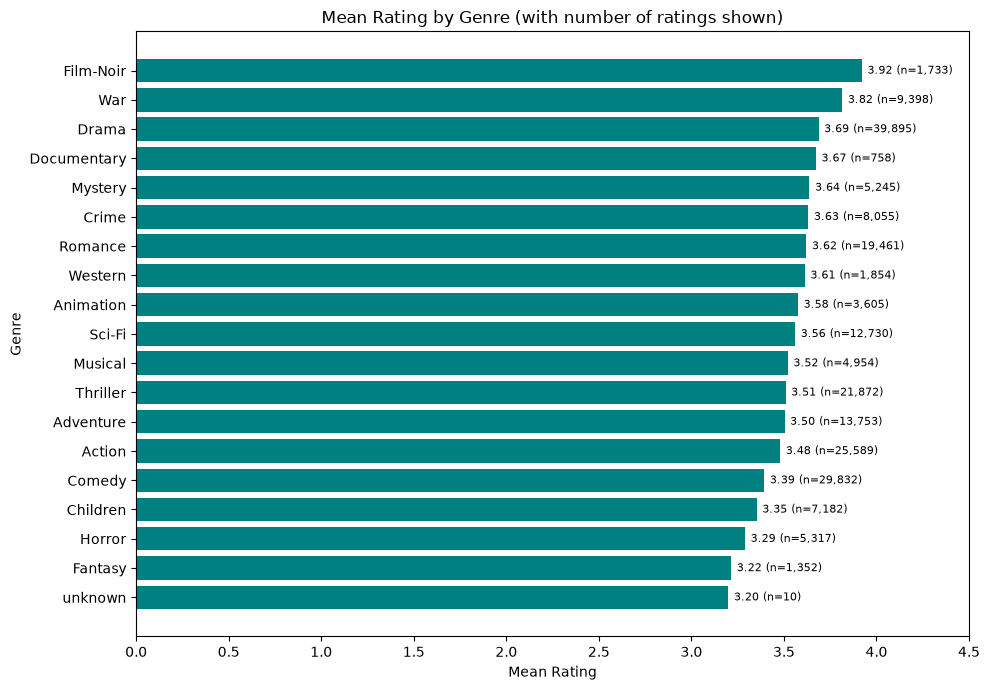

             mean_rating  count  n_movies
genre                                    
Film-Noir       3.921523   1733        24
War             3.815812   9398        71
Drama           3.687379  39895       725
Documentary     3.672823    758        50
Mystery         3.638132   5245        61
Crime           3.632278   8055       109
Romance         3.621705  19461       247
Western         3.613269   1854        27
Animation       3.576699   3605        42
Sci-Fi          3.560723  12730       101
Musical         3.521397   4954        56
Thriller        3.509007  21872       251
Adventure       3.503527  13753       135
Action          3.480245  25589       251
Comedy          3.394073  29832       505
Children        3.353244   7182       122
Horror          3.290389   5317        92
Fantasy         3.215237   1352        22
unknown         3.200000     10         2


In [18]:
# Q2: Genre satisfaction — mean rating + count per genre
genre_stats = genre_df.groupby('genre').agg(
    mean_rating=('rating', 'mean'),
    count=('rating', 'count'),
    n_movies=('movie_id', 'nunique')
).sort_values('mean_rating', ascending=False)

# Bar chart with count annotation — x-axis starts at 0 to avoid truncated-axis distortion
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(genre_stats.index[::-1], genre_stats['mean_rating'][::-1], color='teal')
ax.set_xlabel('Mean Rating')
ax.set_ylabel('Genre')
ax.set_title('Mean Rating by Genre (with number of ratings shown)')
ax.set_xlim(0, 4.5)

# Annotate with count
for i, (val, cnt) in enumerate(zip(genre_stats['mean_rating'][::-1], genre_stats['count'][::-1])):
    ax.text(val + 0.03, i, f'{val:.2f} (n={cnt:,})', va='center', fontsize=8)

plt.tight_layout()
plt.show()

print(genre_stats)

**✏️ My answer (with numbers):** The highest-rated genre is **Film-Noir** with a mean of 3.92 (1,733 ratings across 24 movies), followed by **War** at 3.82 (9,398 ratings, 71 movies). The lowest-rated genre (excluding "unknown" which has only 10 ratings) is **Fantasy** at 3.22 (1,352 ratings, 22 movies), followed by **Horror** at 3.29 (5,317 ratings, 92 movies). The top-rated genres (Film-Noir, Documentary) tend to have fewer ratings, so their averages rest on less evidence than the big genres like Drama (3.69, 39,895 ratings) or Comedy (3.39, 29,832 ratings).

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

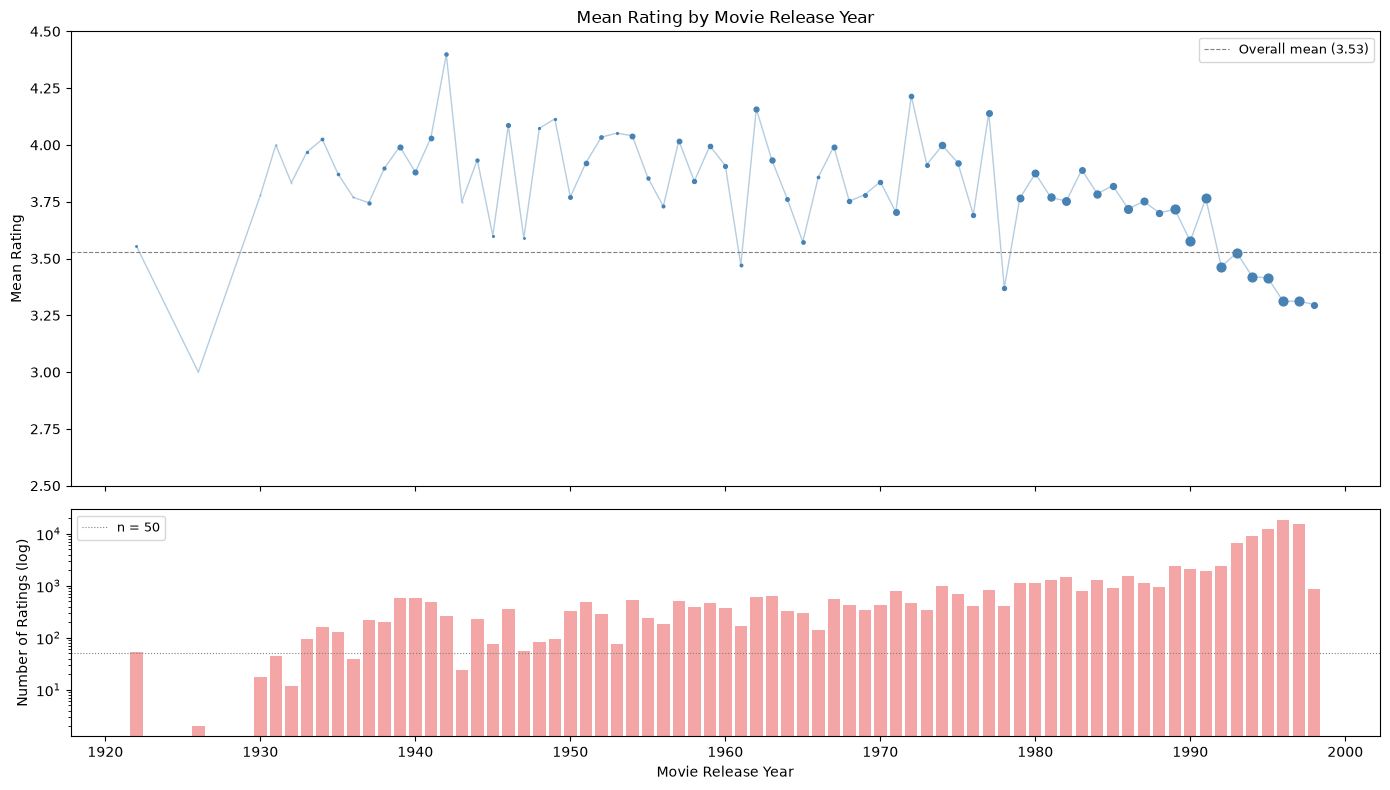

Selected years:
  1930.0: mean=3.778, n=18.0
  1940.0: mean=3.880, n=575.0
  1950.0: mean=3.771, n=332.0
  1960.0: mean=3.909, n=375.0
  1970.0: mean=3.838, n=420.0
  1980.0: mean=3.874, n=1114.0
  1990.0: mean=3.576, n=2092.0
  1995.0: mean=3.415, n=12389.0
  1996.0: mean=3.311, n=18744.0
  1997.0: mean=3.312, n=15384.0
  1998.0: mean=3.297, n=851.0


In [20]:
# Q3: Mean rating by movie release year
# Two stacked panels on a shared x-axis: mean rating on top, count (log scale) below
df_year = df.dropna(subset=['year']).copy()
df_year['year'] = df_year['year'].astype(int)

year_stats = df_year.groupby('year').agg(
    mean_rating=('rating', 'mean'),
    count=('rating', 'count')
).reset_index()

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, height_ratios=[2, 1], figsize=(14, 8))

# Top panel: mean rating, with marker size scaled by n and faded where n < 50
sizes = year_stats['count'].clip(upper=2000) / 50  # scale marker size
colors = ['steelblue' if n >= 50 else 'lightgray' for n in year_stats['count']]
alphas = [1.0 if n >= 50 else 0.4 for n in year_stats['count']]
ax1.plot(year_stats['year'], year_stats['mean_rating'], color='steelblue', linewidth=1, alpha=0.4, zorder=1)
for _, row in year_stats.iterrows():
    a = 1.0 if row['count'] >= 50 else 0.3
    s = min(row['count'] / 50, 40)
    ax1.scatter(row['year'], row['mean_rating'], s=s, color='steelblue', alpha=a, zorder=2)
ax1.set_ylabel('Mean Rating')
ax1.set_ylim(2.5, 4.5)
ax1.set_title('Mean Rating by Movie Release Year')
ax1.axhline(y=df['rating'].mean(), color='gray', linestyle='--', linewidth=0.8, label=f'Overall mean ({df["rating"].mean():.2f})')
ax1.legend(fontsize=9)

# Bottom panel: rating count on log scale
ax2.bar(year_stats['year'], year_stats['count'], color='lightcoral', alpha=0.7, width=0.8)
ax2.set_yscale('log')
ax2.set_ylabel('Number of Ratings (log)')
ax2.set_xlabel('Movie Release Year')
ax2.axhline(y=50, color='gray', linestyle=':', linewidth=0.8, label='n = 50')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Print a summary of key years
print('Selected years:')
for _, row in year_stats[year_stats['year'].isin([1930, 1940, 1950, 1960, 1970, 1980, 1990, 1995, 1996, 1997, 1998])].iterrows():
    print(f"  {row['year']}: mean={row['mean_rating']:.3f}, n={row['count']}")

**✏️ My answer (with numbers):** There is a clear downward trend in mean rating as we move from older to newer release years. Movies from the 1930s–1960s average around 3.7–3.9, while 1990s movies average about 3.3. However, this trend is **not** equally believable across the timeline. Pre-1970 years often have fewer than 500 ratings each (some under 50), making those averages very noisy. The bulk of the data sits in 1994–1997 (e.g., 1996 alone has 18,744 ratings). The apparent superiority of older movies likely reflects **survivorship bias**: the only old movies in this dataset are well-known classics that people sought out to rate in 1997–98, whereas recent releases include everything — good and bad.

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [21]:
# Q4: Top 5 movies with >= 50 and >= 150 ratings
movie_stats = df.groupby(['movie_id', 'title']).agg(
    mean_rating=('rating', 'mean'),
    count=('rating', 'count')
).reset_index()

# >= 50
top5_50 = movie_stats[movie_stats['count'] >= 50].sort_values(
    ['mean_rating', 'count'], ascending=[False, False]
).head(5)

print('Top 5 movies with >= 50 ratings:')
print(top5_50[['title', 'mean_rating', 'count']].to_string(index=False))

# >= 150
top5_150 = movie_stats[movie_stats['count'] >= 150].sort_values(
    ['mean_rating', 'count'], ascending=[False, False]
).head(5)

print('\nTop 5 movies with >= 150 ratings:')
print(top5_150[['title', 'mean_rating', 'count']].to_string(index=False))

# What changed
dropped = set(top5_50['title']) - set(top5_150['title'])
added = set(top5_150['title']) - set(top5_50['title'])
print(f'\nDropped out: {dropped}')
print(f'Moved in: {added}')

Top 5 movies with >= 50 ratings:
                                                 title  mean_rating  count
                                 Close Shave, A (1995)     4.491071    112
                               Schindler's List (1993)     4.466443    298
                            Wrong Trousers, The (1993)     4.466102    118
                                     Casablanca (1942)     4.456790    243
Wallace & Gromit: The Best of Aardman Animation (1996)     4.447761     67

Top 5 movies with >= 150 ratings:
                           title  mean_rating  count
         Schindler's List (1993)     4.466443    298
               Casablanca (1942)     4.456790    243
Shawshank Redemption, The (1994)     4.445230    283
              Rear Window (1954)     4.387560    209
      Usual Suspects, The (1995)     4.385768    267

Dropped out: {'Close Shave, A (1995)', 'Wrong Trousers, The (1993)', 'Wallace & Gromit: The Best of Aardman Animation (1996)'}
Moved in: {'Shawshank Redemption, Th

**✏️ My answer (with numbers):** With a ≥50 floor, the top 5 are: **A Close Shave** (4.491, n=112), **Schindler's List** (4.466, n=298), **Wrong Trousers** (4.466, n=118), **Casablanca** (4.457, n=243), and **Wallace & Gromit: Best of Aardman** (4.448, n=67). When the floor rises to ≥150, three Wallace & Gromit / Aardman films drop out (they had 67–118 ratings), and **Shawshank Redemption** (4.445, n=283), **Rear Window** (4.388, n=209), and **The Usual Suspects** (4.386, n=267) move in. This illustrates the small-sample problem: movies with fewer ratings can achieve very high averages because a handful of fans skew the mean, but these averages are less stable. Raising the floor forces more evidence behind each entry and surfaces broadly acclaimed films.

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked: _(fill in from your Week 4 build log)_
- AI's first attempt: _(fill in)_
- What I changed (or accepted without checking): _(fill in)_

**Prompt 2**
- What I asked: _(fill in from your Week 4 build log)_
- AI's first attempt: _(fill in)_
- What I changed (or accepted without checking): _(fill in)_

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says: _(fill in after opening your dashboard)_
- I say: Drama leads with 39,895 ratings, then Comedy (29,832), Action (25,589). 19 genres total.
- Same? (yes / partly / no): _(fill in)_
- If different, why? _(fill in)_

**Q2**
- Dashboard says: _(fill in)_
- I say: Film-Noir highest (3.92), Fantasy lowest (3.22, excluding unknown).
- Same? (yes / partly / no): _(fill in)_
- If different, why? _(fill in)_

**Q3**
- Dashboard says: _(fill in)_
- I say: Older movies rate higher (~3.8–3.9) vs. recent (~3.3), but early years have tiny samples.
- Same? (yes / partly / no): _(fill in)_
- If different, why? _(fill in)_

**Q4**
- Dashboard says: _(fill in)_
- I say: ≥50: Close Shave, Schindler's List, Wrong Trousers, Casablanca, Wallace & Gromit. ≥150: Schindler's List, Casablanca, Shawshank, Rear Window, Usual Suspects.
- Same? (yes / partly / no): _(fill in)_
- If different, why? _(fill in)_

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

_(fill in after comparing with your dashboard)_

## 3.3 Chart choices

**Q1**
- Chart the dashboard used: Horizontal bar chart
- Chart I used: Horizontal bar chart, sorted by count, with count labels on each bar.
- Which communicates the answer better, and why? I agree on the use of the horizontal bar since we are getting the count of the movie but if we are going to see the percentage I would use a pi chart.

**Q2**
- Chart the dashboard used: _(fill in)_
- Chart I used: Horizontal bar chart sorted by mean rating, x-axis starting at 0 (not truncated), with count annotations showing sample size.
- Which communicates the answer better, and why? _(fill in)_

**Q3**
- Chart the dashboard used:  Two stacked panels sharing an x-axis — top panel shows mean rating as a scatter/line plot (with marker size scaled by n and faded where n < 50), bottom panel shows rating count on a log scale so small-sample years stay visible.
- Chart I used: split the stacked panels and the shring x-axis
- Which communicates the answer better, and why? I think mine is better since it more visiable and easier to read than the dashboard use since with the overlay the line could get confuse

**Q4**
- Chart the dashboard used: _(fill in)_
- Chart I used: Printed tables with title, mean rating, and count. A table is the right choice here because we're showing a ranked list of 5 items with exact values — a chart would add visual complexity without aiding comparison.
- Which communicates the answer better, and why? _(fill in)_

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

In [ ]:
# Supporting code for 3.4
import numpy as np

# Q1: Who is in this data?
user_counts = df.groupby('user_id').size()
print('Min ratings per user:', user_counts.min())
print('Max ratings per user:', user_counts.max())
print('Median ratings per user:', user_counts.median())
print('Gender:', df.groupby('user_id')['gender'].first().value_counts().to_dict())
print('Rating years:', sorted(df['rating_year'].unique()))
print()

# Q2: 95% CI for Fantasy (lowest-rated genre excluding unknown)
fantasy = genre_df[genre_df['genre'] == 'Fantasy']['rating']
n = len(fantasy)
mean = fantasy.mean()
std = fantasy.std()
se = std / np.sqrt(n)
print(f'Fantasy: mean={mean:.3f}, std={std:.3f}, n={n}, n_movies={genre_df[genre_df["genre"]=="Fantasy"]["movie_id"].nunique()}')
print(f'95% CI: [{mean - 1.96*se:.3f}, {mean + 1.96*se:.3f}]')
print()

# Q4: Two ways to average
# (a) grand mean of all ratings
avg_a = genre_df.groupby('genre')['rating'].mean().sort_values(ascending=False)
# (b) mean of movie means
movie_genre = genre_df.groupby(['genre', 'movie_id'])['rating'].mean().reset_index()
avg_b = movie_genre.groupby('genre')['rating'].mean().sort_values(ascending=False)
print('Method (a) top 5:', avg_a.head(5).to_dict())
print('Method (b) top 5:', avg_b.head(5).to_dict())

**1. Who is in this data?** Every user gave at least 20 ratings (minimum enforced by the dataset) and the most prolific user gave 737. The 943 users are 71% male, skewed toward students and tech workers, and all rated movies in just 1997–1998. This is a self-selected sample of early internet movie enthusiasts — casual viewers, older adults, and people without internet access in the late 1990s are missing. This likely tilts Q2 toward genres favored by young tech-savvy males (e.g., Sci-Fi, Action might be rated more generously than in the general population, while genres like Romance or Musical might score lower).

**2. How sure are you about the bottom genre?** Fantasy is the lowest-rated genre at 3.215 with 1,352 ratings across only 22 movies. The 95% CI is [3.156, 3.275], which doesn't overlap with Horror's CI of [3.258, 3.322], so Fantasy does appear statistically lower. However, 1,352 ratings spread over just 22 movies means each movie contributes ~61 ratings on average — the ratings are not truly independent. If a few of those 22 movies happen to be poorly received, they drag down the entire genre. I wouldn't confidently bet Fantasy is "truly the worst" based on 22 movies.

**4. Does "average" depend on how you average?** Yes. Method (a) — averaging all ratings — gives Film-Noir (3.92), War (3.82), Drama (3.69). Method (b) — averaging movie averages — gives Film-Noir (3.55), War (3.49), Musical (3.38). The top genre stays Film-Noir either way, but the values drop substantially in method (b), and the rankings shift (e.g., Musical jumps from 11th to 3rd). This is because method (a) weights heavily-rated movies more: a popular Film-Noir with 500 ratings at 4.2 dominates the genre average, but in method (b) it counts the same as a niche Film-Noir with 5 ratings at 2.0. These answer different questions: (a) = "what rating does the typical *viewer* of this genre give?" vs. (b) = "what's the typical quality of a *movie* in this genre?"

## 3.5 Verdict

**Where I'd override the AI** _(fill in after comparing with your dashboard)_:

**Where the AI held up** _(fill in)_:

**One sentence:** _(fill in)_

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week